# 02 - Preprocessing: DDR Dataset

Kiểm tra từng bước (crop, resize, CLAHE, normalize, augmentation) và 4 cấu hình E1-E4 trên ảnh thật.
Code nằm trong `src/preprocessing.py`, `src/normalization.py`, `src/augmentation.py`, `src/pipelines.py`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import numpy as np
import torch

from src import config, visualization as viz
viz.set_style()
from src.dataset import load_split, read_image_rgb
from src.preprocessing import crop_retina, resize_image, apply_clahe
from src.normalization import Normalizer
from src.augmentation import TrainAugmentation, get_augmentation
from src.pipelines import CONFIGS, build_pipeline

# mỗi class 1 ảnh train, chọn ngẫu nhiên có seed
rng = np.random.default_rng(config.SEED)
train = load_split("train")
samples = []
for label in config.CLASS_NAMES:
    pool = [s for s in train if s.label == label]
    samples.append(pool[rng.integers(len(pool))])
[s.filename for s in samples]

['20170214220640168.jpg',
 '007-2349-100.jpg',
 '007-2393-100.jpg',
 '007-3360-200.jpg',
 '007-6743-400.jpg']

## 1. Retinal crop

Grayscale → threshold so với mức nền → thành phần liên thông lớn nhất → bounding box. Không tìm được vùng hợp lệ thì trả về ảnh gốc.

original: (1728, 2592, 3) -> cropped: (1612, 1612, 3) {'bbox': (490, 60, 2102, 1667), 'cropped': True}


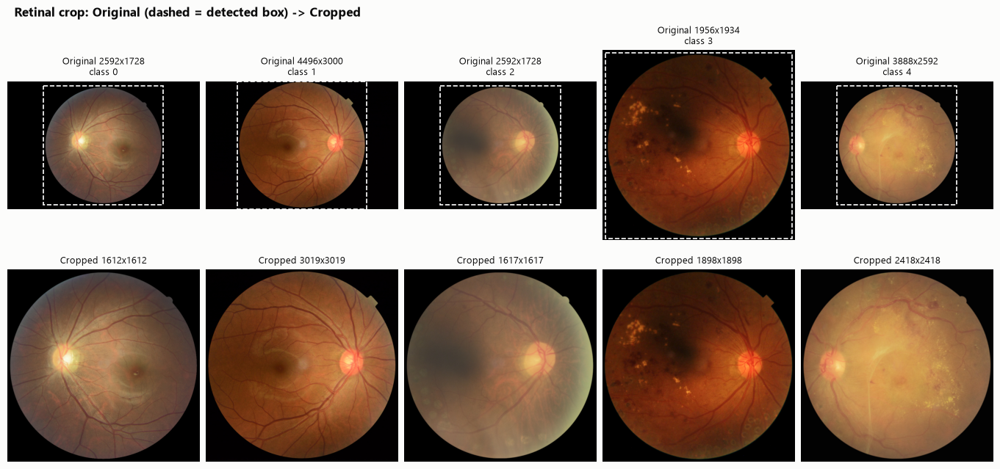

In [2]:
image = read_image_rgb(samples[0].path)
cropped, info = crop_retina(image, return_info=True)
print("original:", image.shape, "-> cropped:", cropped.shape, info)
viz.plot_crop_examples(samples, config.PREPROCESS_DIR / "01_crop.png");

## 2. Resize 224×224

(224, 224, 3) uint8


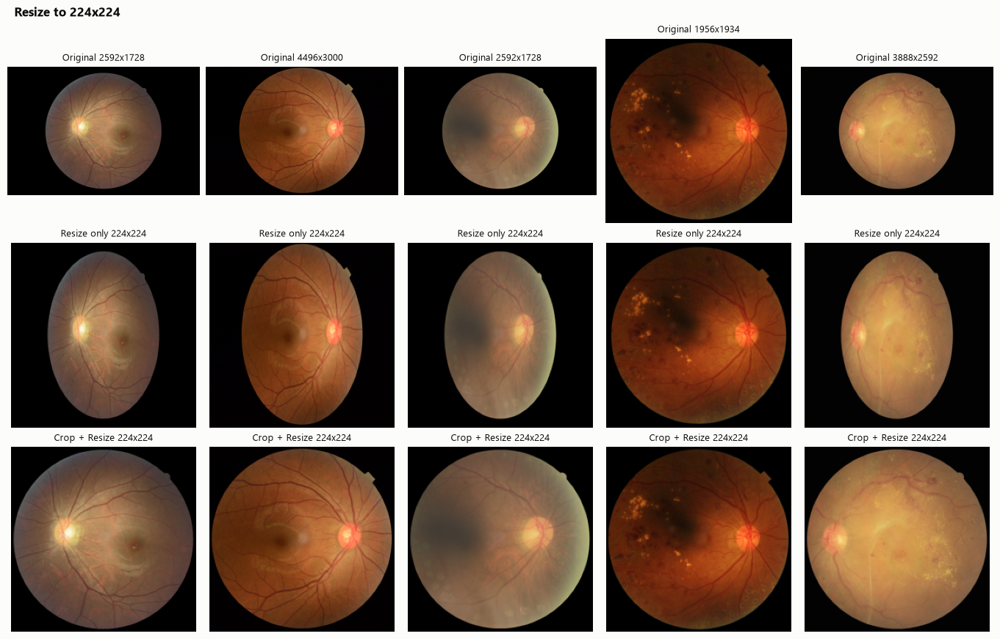

In [3]:
resized = resize_image(cropped)
print(resized.shape, resized.dtype)
viz.plot_resize_check(samples, config.PREPROCESS_DIR / "02_resize.png");

## 3. CLAHE (kênh L của LAB)

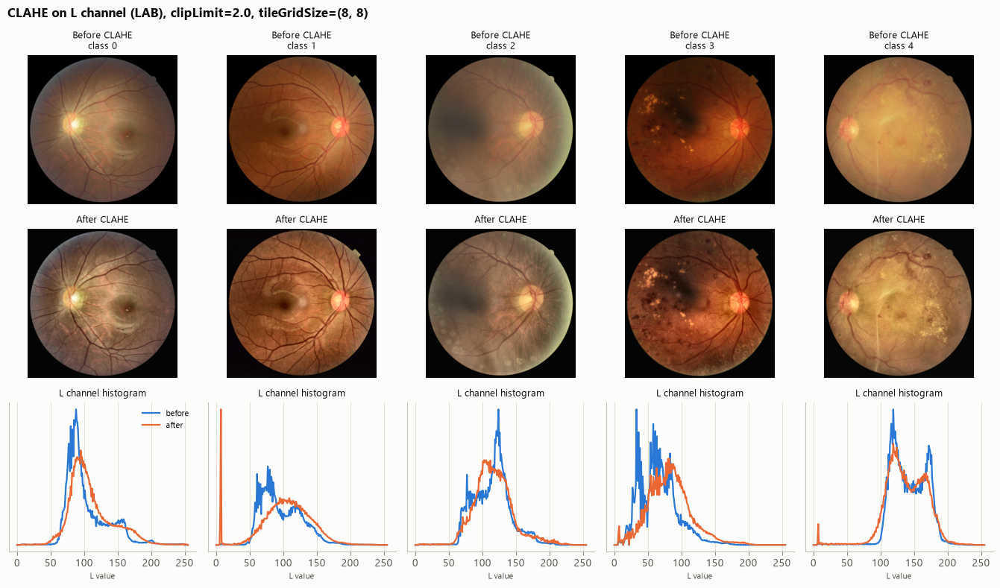

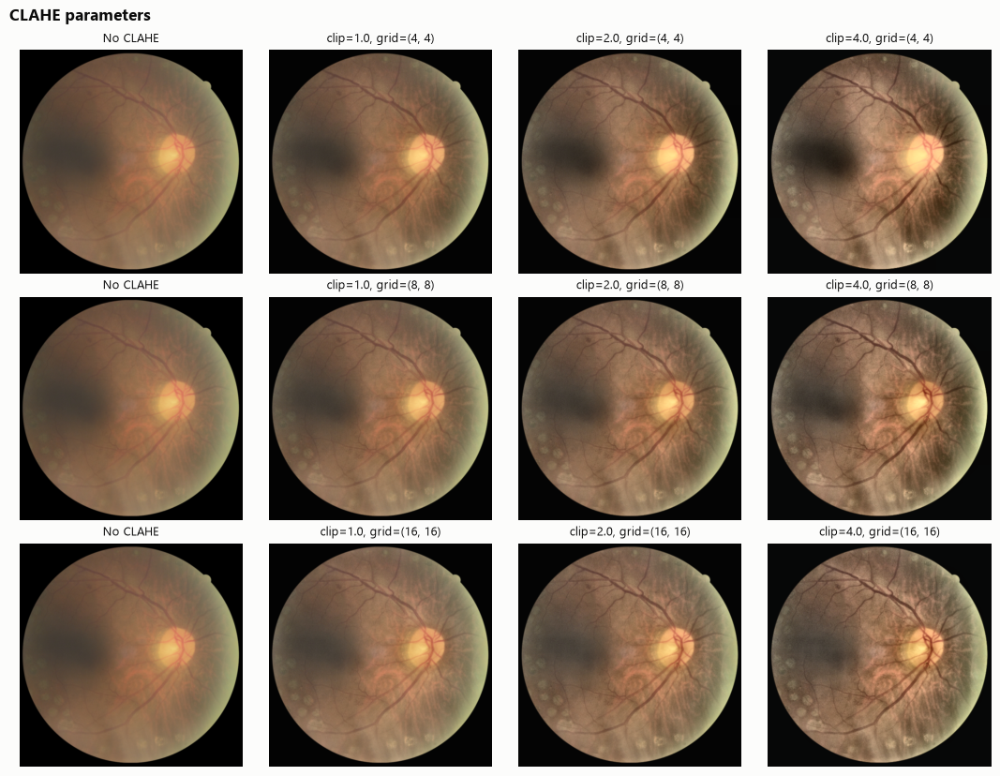

In [4]:
viz.plot_clahe_examples(samples, clip_limit=config.CLAHE_CLIP_LIMIT, tile_grid_size=config.CLAHE_TILE_GRID_SIZE,
                        save_path=config.PREPROCESS_DIR / "03_clahe.png")
viz.plot_clahe_params(samples[2], save_path=config.PREPROCESS_DIR / "03_clahe_params.png");

## 4. Normalization

Mean/std cấu hình tại `config.NORMALIZATION`. `Normalizer` chỉ nhận ảnh uint8, nên normalize lần hai sẽ báo lỗi.

Normalizer(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
torch.Size([3, 224, 224]) torch.float32 range [-2.118, 2.341]
Normalize lần 2 -> TypeError


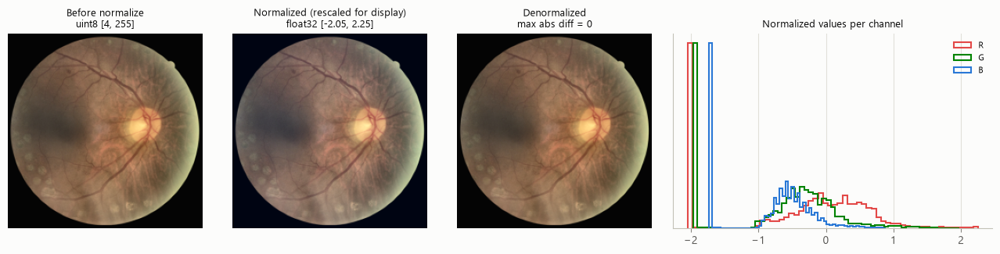

In [5]:
normalizer = Normalizer()
tensor = normalizer(resized)
print(normalizer)
print(tensor.shape, tensor.dtype, "range [%.3f, %.3f]" % (tensor.min(), tensor.max()))
try:
    normalizer(tensor)
except TypeError as e:
    print("Normalize lần 2 ->", type(e).__name__)
viz.plot_normalization_check(samples[2], config.PREPROCESS_DIR / "04_normalize.png");

## 5. Augmentation (chỉ training)

train: TrainAugmentation | valid: None | test: None
AugmentationConfig(hflip_prob=0.5, rotation_degrees=15.0, zoom_range=(0.9, 1.1), brightness=0.1, contrast=0.1)


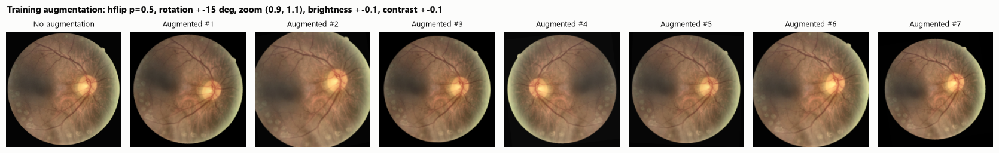

In [6]:
print("train:", type(get_augmentation("train")).__name__, "| valid:", get_augmentation("valid"),
      "| test:", get_augmentation("test"))
print(config.AUGMENTATION)
viz.plot_augmentation_examples(samples[2], save_path=config.PREPROCESS_DIR / "05_augmentation.png");

## 6. Toàn bộ pipeline theo từng bước

Thứ tự thực thi: Original → Crop → CLAHE → Resize → Augmentation → Normalize.

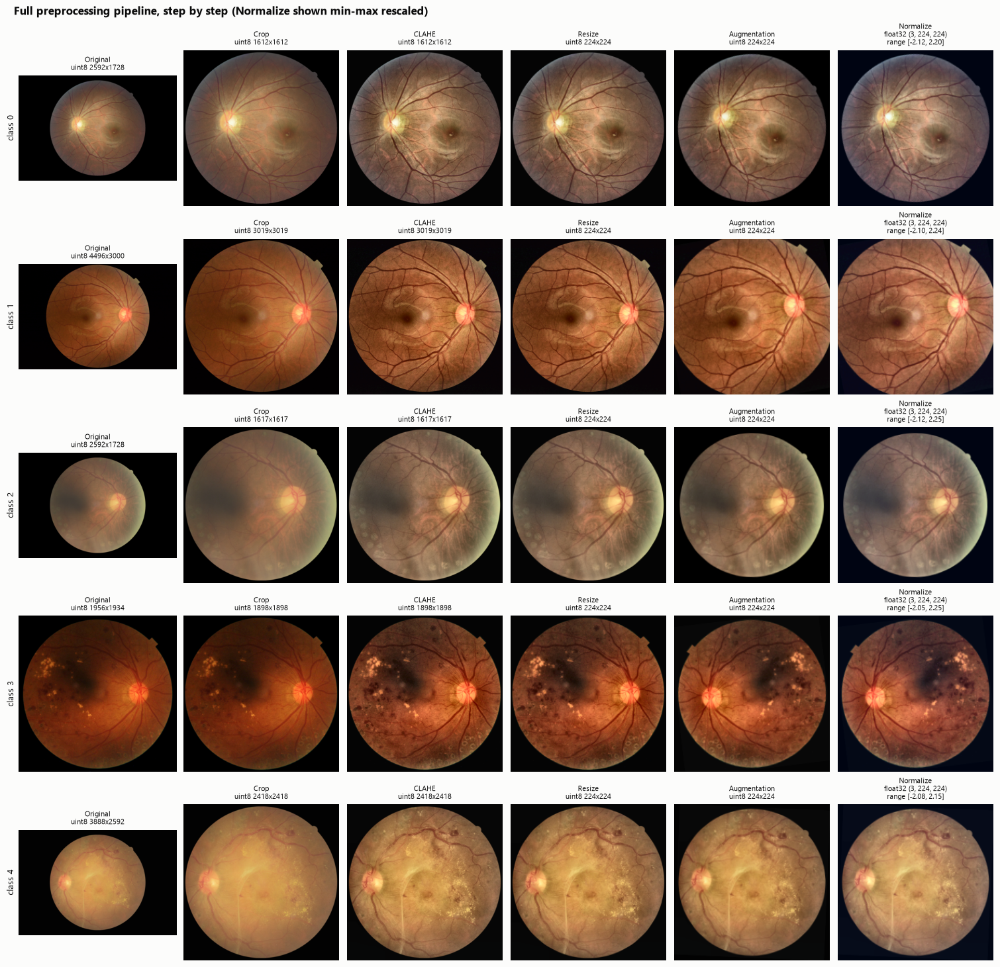

In [7]:
viz.plot_pipeline_stages(samples, save_path=config.PREPROCESS_DIR / "06_pipeline_stages.png");

## 7. Bốn cấu hình E1-E4

E1 [train] Resize                       augment=False -> (3, 224, 224) torch.float32
E1 [valid] Resize                       augment=False -> (3, 224, 224) torch.float32
E2 [train] Crop + Resize                augment=False -> (3, 224, 224) torch.float32
E2 [valid] Crop + Resize                augment=False -> (3, 224, 224) torch.float32


E3 [train] Crop + CLAHE + Resize        augment=False -> (3, 224, 224) torch.float32
E3 [valid] Crop + CLAHE + Resize        augment=False -> (3, 224, 224) torch.float32


E4 [train] Crop + CLAHE + Augmentation  augment=True  -> (3, 224, 224) torch.float32
E4 [valid] Crop + CLAHE + Augmentation  augment=False -> (3, 224, 224) torch.float32


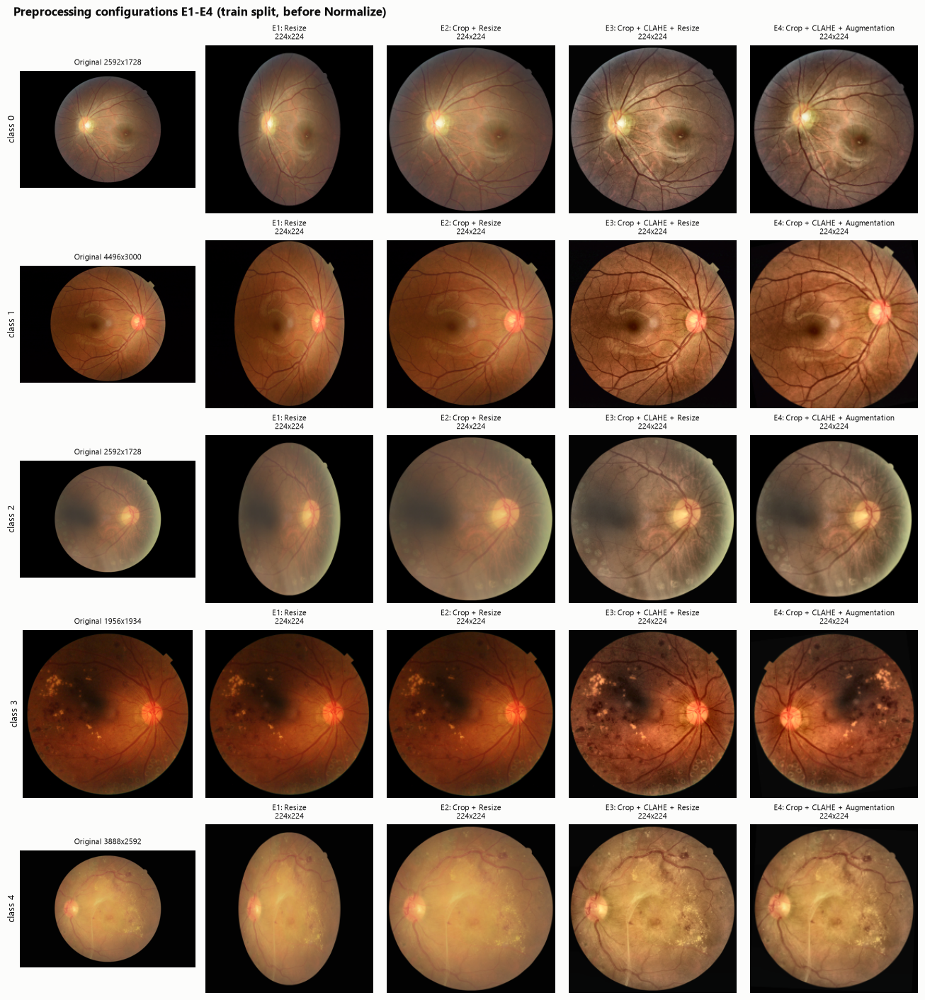

In [8]:
for name, cfg in CONFIGS.items():
    for split in ("train", "valid"):
        pipeline = build_pipeline(name, split=split)
        out = pipeline(image)
        print(f"{name} [{split:<5}] {cfg.description:<28} augment={pipeline.augmentation is not None!s:<5} "
              f"-> {tuple(out.shape)} {out.dtype}")
viz.plot_config_comparison(samples, save_path=config.PREPROCESS_DIR / "07_configs_E1_E4.png");